<a href="https://colab.research.google.com/github/Greeshma-S-Kunder/AML_LAB_assignments/blob/main/Machine_learning_lab_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']
                              name  year  selling_price  km_driven    fuel  \
0           Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1     Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2         Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3        Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4           Maruti Swift VXI BSIII  2007         130000     120000  Petrol   
...                            ...   ...            ...        ...     ...   
8123             Hyundai i20 Magna  2013         320000     110000  Petrol   
8124         Hyundai Verna CRDi SX  2007         135000     119000  Diesel   
8125        Maruti Swift Dzire ZDi  2009         382000     120000  Diesel   
8126               Tata Indigo CR4  2013         290000      25000  Dies

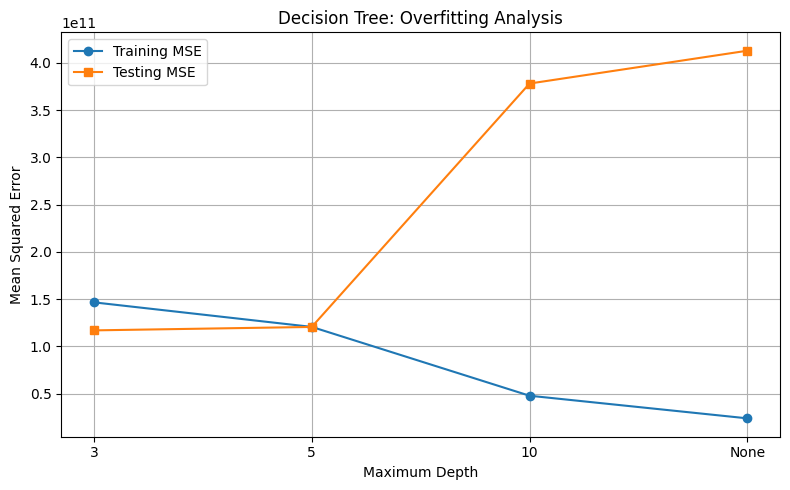

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

df = pd.read_csv("Car details v3.csv")
print(df.columns.tolist())
print(df)

features = [
    "year", "km_driven", "fuel",
    "seller_type", "transmission", "owner"
]

df = df[features + ["selling_price"]].copy()

for col in ["year", "km_driven", "selling_price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()
df = df[df["selling_price"] > 0]
df = df.drop_duplicates()

X = df[features]
y = df["selling_price"]
print(df)

X = pd.get_dummies(
    X,
    columns=["fuel", "seller_type", "transmission", "owner"],
    dtype=int
)

# Split into training, validation and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

depths = [3, 5, 10, None]
depth_results = {}
depth_models = {}

print("\nDecision Tree Depth Comparison")

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)
    depth_models[depth] = model
    depth_results[depth] = {
          "Training MSE": train_mse,
          "Testing MSE": test_mse
      }

    print(
          f"Depth: {str(depth):>4} | "
          f"Training MSE: {train_mse:.2f} | "
          f"Testing MSE: {test_mse:.2f}"
      )
plt.figure(figsize=(8, 5))

labels = [str(d) for d in depths]
train_errors = [
    depth_results[d]["Training MSE"] for d in depths
]
test_errors = [
    depth_results[d]["Testing MSE"] for d in depths
]

plt.plot(labels, train_errors, marker="o", label="Training MSE")
plt.plot(labels, test_errors, marker="s", label="Testing MSE")

plt.xlabel("Maximum Depth")
plt.ylabel("Mean Squared Error")
plt.title("Decision Tree: Overfitting Analysis")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [ ]:
print("\nPART (b): Cost-Complexity Pruning")

# Generate candidate alpha values from training data
initial_tree = DecisionTreeRegressor(random_state=42)
path = initial_tree.cost_complexity_pruning_path(
    X_train, y_train
)

alphas = path.ccp_alphas

best_alpha = None
best_val_mse = float("inf")
best_pruned_model = None

for alpha in alphas:
    model = DecisionTreeRegressor(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    val_mse = mean_squared_error(y_val, val_pred)

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_alpha = alpha
        best_pruned_model = model

unpruned_model = depth_models[None]

unpruned_test_mse = mean_squared_error(
    y_test, unpruned_model.predict(X_test)
)

pruned_test_mse = mean_squared_error(
    y_test, best_pruned_model.predict(X_test)
)

print("Selected ccp_alpha:", best_alpha)
print("Best validation MSE:", best_val_mse)

print("\nModel Comparison")
print(
    f"Unpruned Tree Test MSE: {unpruned_test_mse:.2f}"
)
print(
    f"Pruned Tree Test MSE:   {pruned_test_mse:.2f}"
)

print(
    "Unpruned tree depth:",
    unpruned_model.get_depth()
)
print(
    "Pruned tree depth:",
    best_pruned_model.get_depth()
)
print(
    "Unpruned leaf nodes:",
    unpruned_model.get_n_leaves()
)
print(
    "Pruned leaf nodes:",
    best_pruned_model.get_n_leaves()
)




PART (b): Cost-Complexity Pruning
Selected ccp_alpha: 1263825911.9296737
Best validation MSE: 92932818968.08849

Model Comparison
Unpruned Tree Test MSE: 412727976313.17
Pruned Tree Test MSE:   349702640286.44
Unpruned tree depth: 27
Pruned tree depth: 9
Unpruned leaf nodes: 2361
Pruned leaf nodes: 28


In [ ]:
print("\nPART (c): Model Selection")

if pruned_test_mse < unpruned_test_mse:
    best_model = best_pruned_model
    print("The pruned tree performs better on the test set.")
elif unpruned_test_mse < pruned_test_mse:
    best_model = unpruned_model
    print("The unpruned tree performs better on the test set.")
else:
    best_model = best_pruned_model
    print("Both models have equal test MSE.")

print(
    "Selected model test MSE:",
    min(unpruned_test_mse, pruned_test_mse)
)


PART (c): Model Selection
The pruned tree performs better on the test set.
Selected model test MSE: 349702640286.4403


In [ ]:
print("\nPART (d): Vehicle Price Prediction")

# Select one vehicle from the test set
vehicle_index = 0
vehicle = X_test.iloc[[vehicle_index]]

actual_price = y_test.iloc[vehicle_index]
predicted_price = best_model.predict(vehicle)[0]

print("\nVehicle features:")
print(vehicle.T)

print(f"\nActual selling price: {actual_price:,.2f}")
print(f"Predicted selling price: {predicted_price:,.2f}")
print(
    f"Absolute prediction error: "
    f"{abs(actual_price - predicted_price):,.2f}"
)


PART (d): Vehicle Price Prediction

Vehicle features:
                                3004
year                            2010
km_driven                     100000
fuel_CNG                           0
fuel_Diesel                        1
fuel_LPG                           0
fuel_Petrol                        0
seller_type_Dealer                 0
seller_type_Individual             1
seller_type_Trustmark Dealer       0
transmission_Automatic             0
transmission_Manual                1
owner_First Owner                  1
owner_Fourth & Above Owner         0
owner_Second Owner                 0
owner_Test Drive Car               0
owner_Third Owner                  0

Actual selling price: 220,000.00
Predicted selling price: 213,598.51
Absolute prediction error: 6,401.49
